In [1]:
import time, json, warnings
import numpy as np, pandas as pd
from pathlib import Path
warnings.filterwarnings("ignore")
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, matthews_corrcoef, confusion_matrix)

P = Path("processed"); B = P / "balanced"
X_val = np.load(P / "X_val.npy"); y_val = np.load(P / "y_val.npy")

sets = ["none", "class_weight", "random_over", "random_under", "smote",
        "borderline_smote", "adasyn", "under_then_smote",
        "smote_tomek", "smote_enn", "tomek_links"]

In [2]:
rows, cms = [], {}
for s in sets:
    d = np.load(B / ("none.npz" if s == "class_weight" else f"{s}.npz"))
    X, y = d["X"], d["y"]
    lr = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, random_state=42,
                            class_weight="balanced" if s == "class_weight" else None)
    t = time.time(); lr.fit(X, y); fit_s = time.time() - t

    pred = lr.predict(X_val); prob = lr.predict_proba(X_val)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    cms[s] = [[int(tn), int(fp)], [int(fn), int(tp)]]
    rows.append({
        "set": s, "train_rows": len(y),
        "accuracy": accuracy_score(y_val, pred),
        "precision": precision_score(y_val, pred),
        "recall_attack": recall_score(y_val, pred),
        "normal_recall": tn / (tn + fp),
        "f1": f1_score(y_val, pred),
        "macro_f1": f1_score(y_val, pred, average="macro"),
        "pr_auc": average_precision_score(y_val, prob),
        "roc_auc": roc_auc_score(y_val, prob),
        "mcc": matthews_corrcoef(y_val, pred),
        "FPR": fp / (fp + tn), "FNR": fn / (fn + tp),
        "iters": int(lr.n_iter_[0]), "fit_s": fit_s})
    print(s, "done")

results = pd.DataFrame(rows).sort_values("mcc", ascending=False)
results.round(4)

none done
class_weight done
random_over done
random_under done
smote done
borderline_smote done
adasyn done
under_then_smote done
smote_tomek done
smote_enn done
tomek_links done


,set,train_rows,accuracy,precision,recall_attack,normal_recall,f1,macro_f1,pr_auc,roc_auc,mcc,FPR,FNR,iters,fit_s
0,none,140311,0.9628,0.9699,0.9876,0.8045,0.9787,0.9165,0.9959,0.9771,0.8351,0.1955,0.0124,148,7.6221
10,tomek_links,140193,0.9627,0.9701,0.9873,0.8062,0.9786,0.9165,0.9959,0.9770,0.8351,0.1938,0.0127,128,3.5935
9,smote_enn,236452,0.9271,0.9876,0.9272,0.9259,0.9565,0.8657,0.9964,0.9790,0.7469,0.0741,0.0728,187,8.3479
2,random_over,242568,0.9233,0.9882,0.9223,0.9296,0.9541,0.8604,0.9965,0.9793,0.7387,0.0704,0.0777,204,10.2236
8,smote_tomek,242092,0.9233,0.9881,0.9224,0.9294,0.9541,0.8604,0.9965,0.9792,0.7387,0.0706,0.0776,208,8.7710
4,smote,242568,0.9231,0.9881,0.9221,0.9294,0.9540,0.8601,0.9965,0.9792,0.7381,0.0706,0.0779,196,9.2456
1,class_weight,140311,0.9227,0.9882,0.9216,0.9296,0.9537,0.8595,0.9964,0.9790,0.7372,0.0704,0.0784,171,8.8067
7,under_then_smote,76108,0.9205,0.9882,0.9190,0.9299,0.9524,0.8563,0.9963,0.9785,0.7320,0.0701,0.0810,142,1.8060
3,random_under,38054,0.9201,0.9880,0.9187,0.9291,0.9521,0.8557,0.9962,0.9778,0.7309,0.0709,0.0813,113,0.9347
5,borderline_smote,242568,0.7760,0.9919,0.7469,0.9612,0.8522,0.6950,0.9935,0.9621,0.5086,0.0388,0.2531,297,13.3675


In [3]:
results.round(4).to_csv(P / "lr_results.csv", index=False)
json.dump(cms, open(P / "lr_confusion.json", "w"))

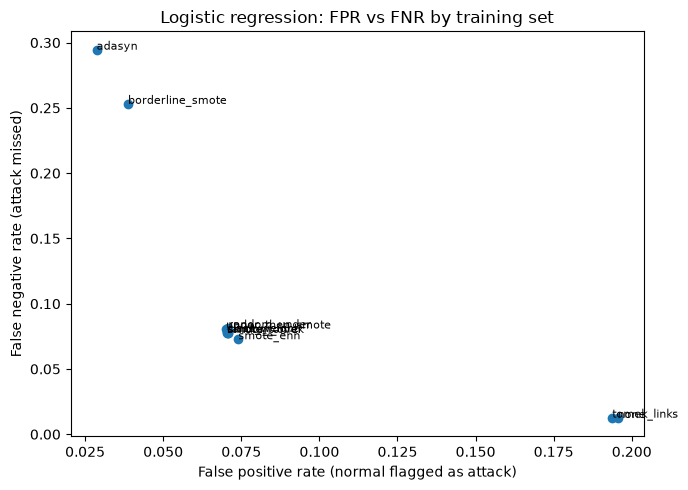

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(results["FPR"], results["FNR"])
for _, r in results.iterrows():
    ax.annotate(r["set"], (r["FPR"], r["FNR"]), fontsize=8)
ax.set_xlabel("False positive rate (normal flagged as attack)")
ax.set_ylabel("False negative rate (attack missed)")
ax.set_title("Logistic regression: FPR vs FNR by training set")
plt.tight_layout(); plt.savefig(P / "lr_tradeoff.png", dpi=150); plt.show()